## GCN regression

In [76]:
import pandas as pd
import numpy as np
import plotly.express as px
import numpy as np
import plotly.graph_objects as go
import seaborn as sns
import matplotlib.pyplot as plt

### Import data

In [110]:
df = pd.read_csv(r'./data/tot_cost_failure_scenarios_240222.csv')
df_copy = df.copy()

## Visualise data

### Histogram

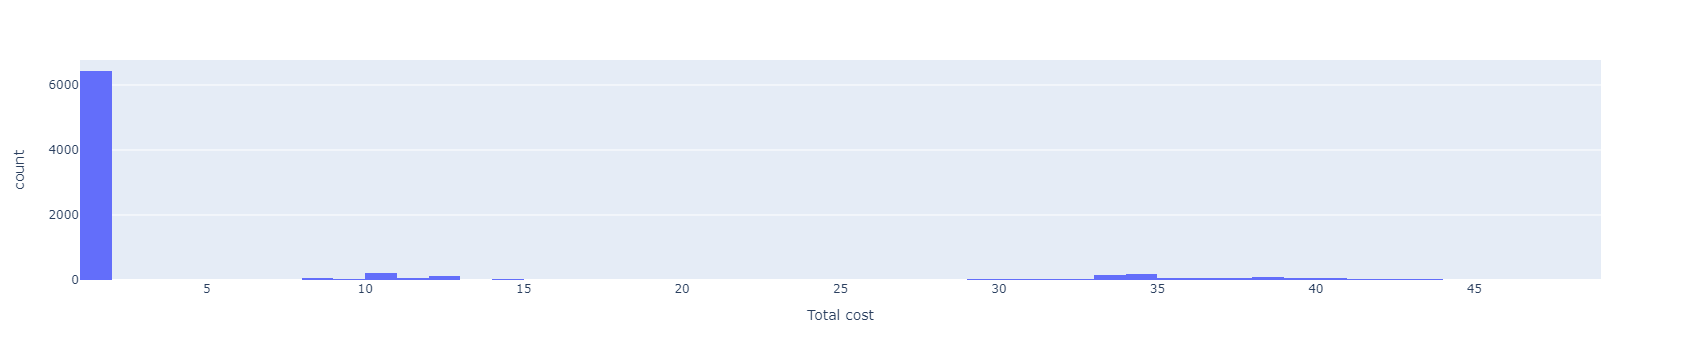

In [111]:
fig = px.histogram(df, x="Total cost")
fig.show()

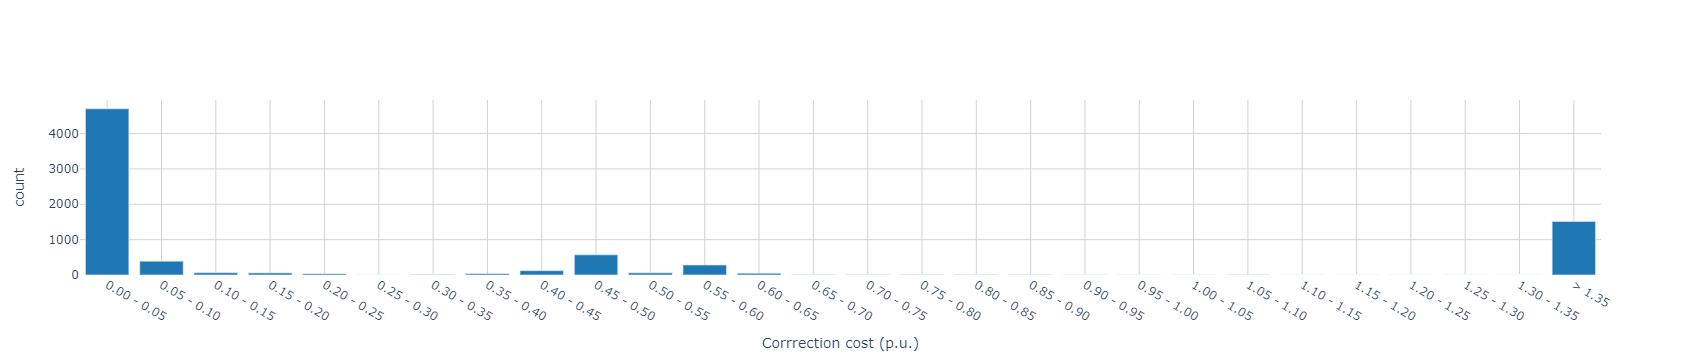

In [79]:
def plot_bar_with_outliers(series, name, end):
    start = int(series.min())
    size = 1

    # Making a histogram
    largest_value = series.max()
    if largest_value > end:
        hist = np.histogram(series, bins=np.concatenate([np.arange(start, end, 0.05), np.array([largest_value])], axis=None))
    else:
        hist = np.histogram(series, bins=np.concatenate([np.arange(start, end, 0.05), np.array([end])], axis=None))

    # Adding labels to the chart
    labels = []
    for i, j in zip(hist[1][0::1], hist[1][1::1]):
        if j <= end:
            labels.append('{:.2f} - {:.2f}'.format(i, j))
        else:
            labels.append('> {:.2f}'.format(i))

    # Plotting the graph
    data = [go.Bar(x=labels,
                   y=hist[0])]

    layout = go.Layout(
        xaxis = dict(
          title = name,
          gridcolor='lightgrey'),
        yaxis = dict(
          title = 'count',
          gridcolor='lightgrey'), 
        paper_bgcolor='rgba(0,0,0,0)',
        plot_bgcolor='rgba(0,0,0,0)'
    )
    fig = go.Figure(data=data, layout=layout)
    fig.update_traces(marker_color='#1F77B4')
    fig.show()

    #iplot(fig, filename='basic histogram')


plot_bar_with_outliers(df['Correction cost'], 'Corrrection cost (p.u.)', end=1.4)

### Correlation plot

Does not seem like any input strongly correlates with correction cost. 

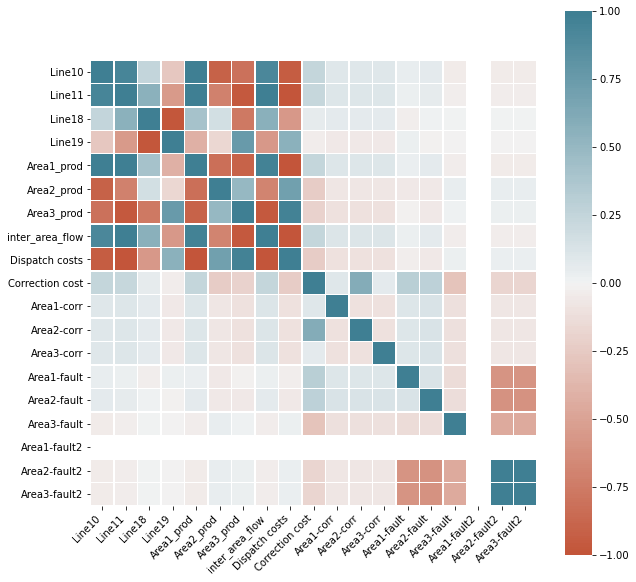

In [80]:
df_ = df[['prev_id', 'Line10', 'Line11', 'Line18', 'Line19', 'Area1_prod', 'Area2_prod', 'Area3_prod', 'inter_area_flow', 'fault', 'corr', 'Dispatch costs', 
          'Correction cost', 'Area1-corr', 'Area2-corr', 'Area3-corr', 'Area1-fault', 'Area2-fault', 'Area3-fault', 'Area1-fault2', 'Area2-fault2', 'Area3-fault2']]

corr = df_.corr()
fig, ax = plt.subplots(figsize=(10,10))  
ax = sns.heatmap(
    corr, 
    vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(20, 220, n=200),
    square=True, linewidths=.5
)
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    horizontalalignment='right'
);

## Run GCN-code

Code runs with `df` defined in Notebook if `df` not defined in `gcn_regression_multidim.py`

In [81]:
%run -i "gcn_regression_multidim.py"

Number of training graphs: 4581
Number of validation graphs: 1292
Number of test graphs: 685
Epoch: 001, Train Acc: 0.892949, Validation Acc: 0.942159
Epoch: 002, Train Acc: 0.881518, Validation Acc: 0.931992
Epoch: 003, Train Acc: 0.885196, Validation Acc: 0.935676
Epoch: 004, Train Acc: 0.879973, Validation Acc: 0.929892
Epoch: 005, Train Acc: 0.876121, Validation Acc: 0.926498
Epoch: 006, Train Acc: 0.882590, Validation Acc: 0.932596
Epoch: 007, Train Acc: 0.878751, Validation Acc: 0.929340
Epoch: 008, Train Acc: 0.873120, Validation Acc: 0.923880
Epoch: 009, Train Acc: 0.873192, Validation Acc: 0.924056
Epoch: 010, Train Acc: 0.870858, Validation Acc: 0.921948
Epoch: 011, Train Acc: 0.872589, Validation Acc: 0.923460
Epoch: 012, Train Acc: 0.878610, Validation Acc: 0.929655
Epoch: 013, Train Acc: 0.873915, Validation Acc: 0.924827
Epoch: 014, Train Acc: 0.876191, Validation Acc: 0.927491
Epoch: 015, Train Acc: 0.871829, Validation Acc: 0.922952
Epoch: 016, Train Acc: 0.873699, Vali

## Results

### Convergence plot

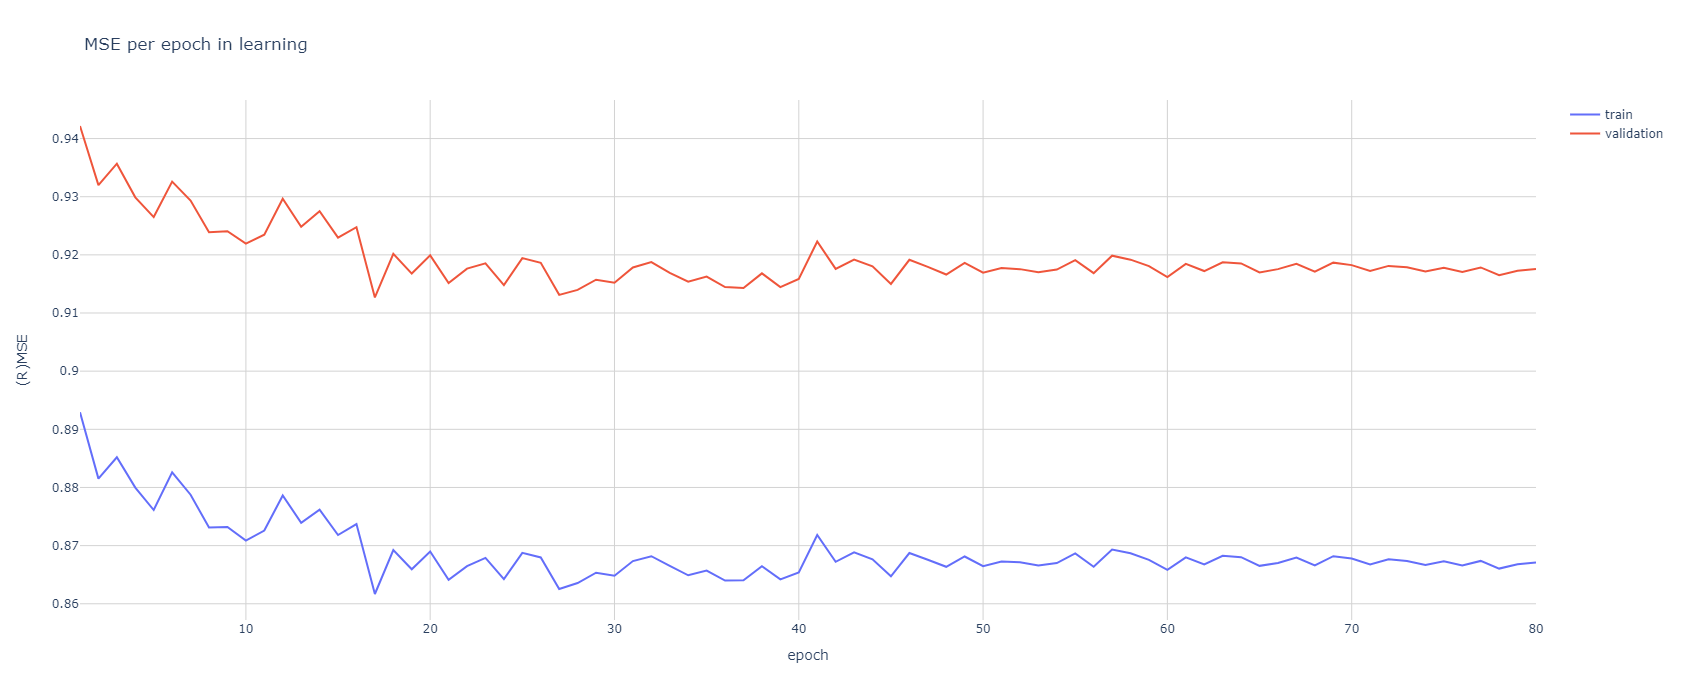

In [83]:
epoch_list = np.arange(1, len(train_list)+1)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=epoch_list,
    y=train_list,
    name="train"
))


fig.add_trace(go.Scatter(
    x=epoch_list,
    y=val_list,
    name="validation"
))

fig.update_layout(
    title="MSE per epoch in learning",
    xaxis_title="epoch",
    yaxis_title="MSE",
     xaxis = dict(
        title = 'epoch',
        gridcolor='lightgrey'),
    yaxis = dict(
        title = '(R)MSE',
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    width=1000,
    height=700
)

fig.show()

## Predicted scenarios sorted by cost

In [85]:
df_results.columns

Index(['prev_id', 'Line10', 'Line11', 'Line18', 'Line19', 'Area1_prod',
       'Area2_prod', 'Area3_prod', 'Area1_load', 'Area2_load', 'Area3_load',
       'inter_area_flow', 'fault', 'corr', 'Dispatch costs', 'CENS',
       'FCR cost', 'Redispatch cost', 'SPS cost', 'Correction cost',
       'Total cost', 'Area1-corr', 'Area2-corr', 'Area3-corr', 'Area1-fault',
       'Area2-fault', 'Area3-fault', 'Area1-fault2', 'Area2-fault2',
       'Area3-fault2', 'inter_area_flow_scaled', 'Area1_prod_scaled',
       'Area2_prod_scaled', 'Area3_prod_scaled', 'Dispatch_cost_target',
       'Correction_cost_target', 'Dispatch_cost_pred', 'Correction_cost_pred'],
      dtype='object')

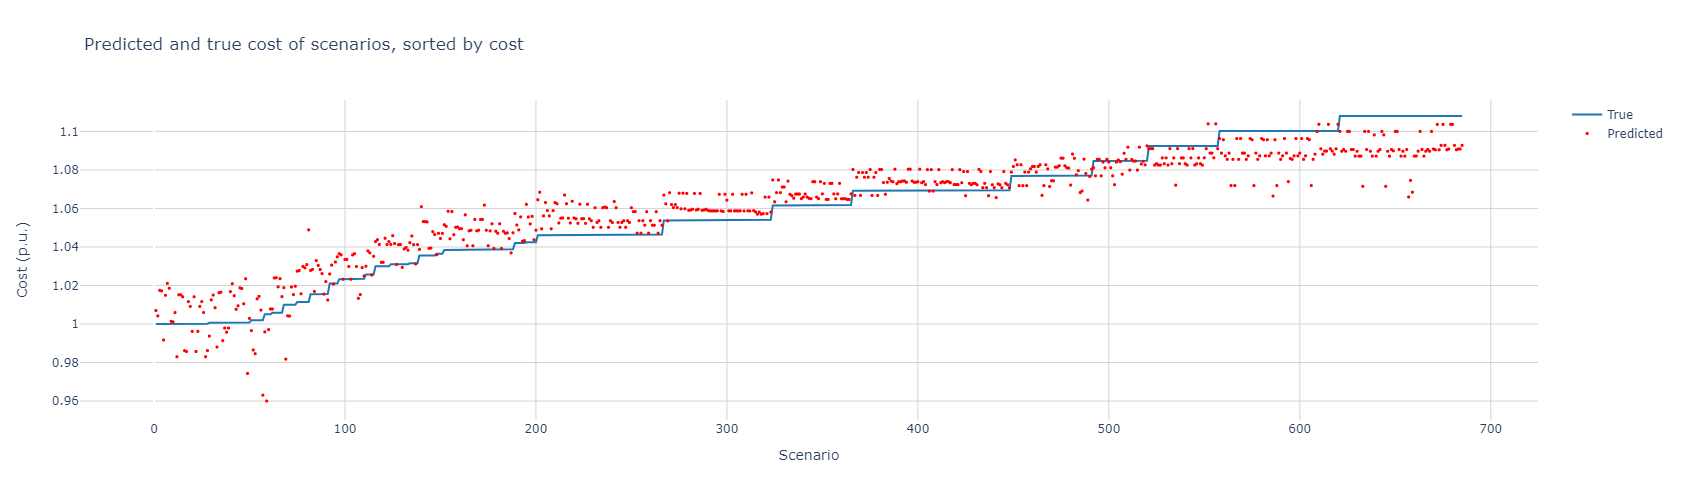

In [86]:
import plotly.graph_objects as go

plot_df = df_results.sort_values(by=['Dispatch_cost_target'])

layout = go.Layout(
    title = f'Predicted and true cost of scenarios, sorted by cost',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

fig.add_trace(go.Scatter(x=x_values, y=plot_df['Dispatch_cost_target'], mode='lines', line=dict(color='#1F77B4'), name="True"))
fig.add_trace(go.Scatter(x=x_values, y=plot_df['Dispatch_cost_pred'], mode='markers', marker=dict(color='red', size=3), name="Predicted"))

fig.update_layout(
    xaxis_title='Scenario',
    yaxis_title='Cost (p.u.)',
    width=700, height=500
)
fig.show()

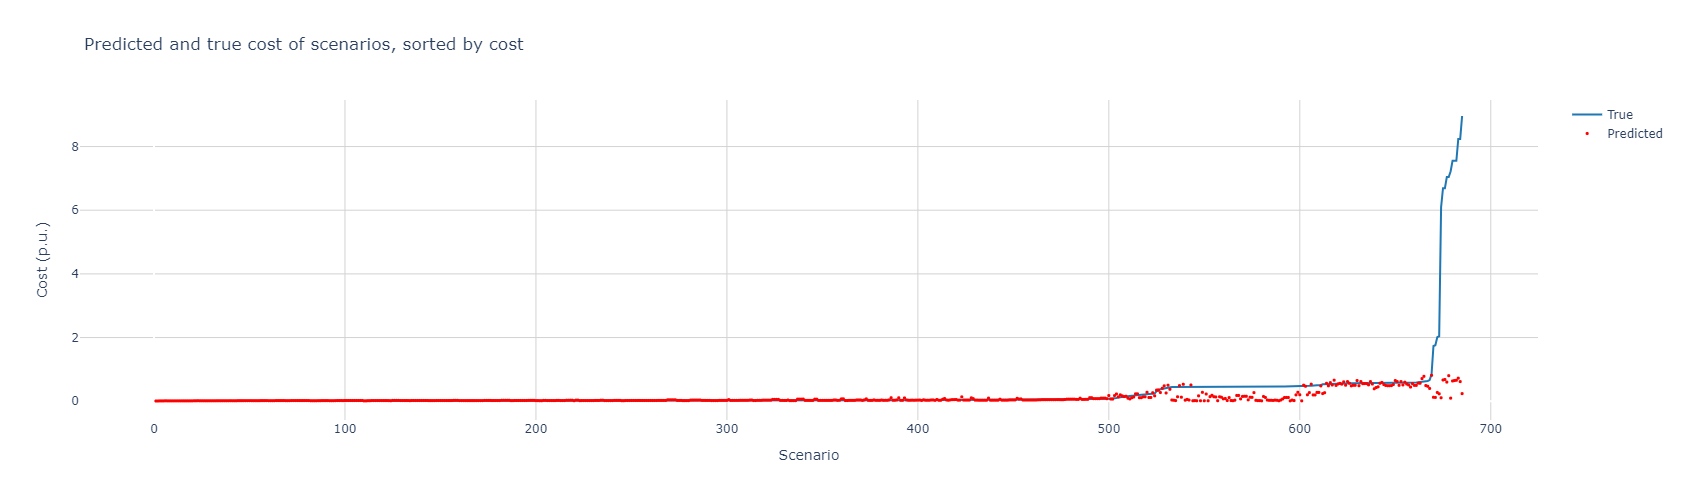

In [87]:
import plotly.graph_objects as go

plot_df = df_results.sort_values(by=['Correction_cost_target'])

layout = go.Layout(
    title = f'Predicted and true cost of scenarios, sorted by cost',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

fig.add_trace(go.Scatter(x=x_values, y=plot_df['Correction_cost_target'], mode='lines', line=dict(color='#1F77B4'), name="True"))
fig.add_trace(go.Scatter(x=x_values, y=plot_df['Correction_cost_pred'], mode='markers', marker=dict(color='red', size=3), name="Predicted"))

fig.update_layout(
    xaxis_title='Scenario',
    yaxis_title='Cost (p.u.)',
    width=700, height=500
)
fig.show()

### Calculate cost per preventive strategy based on results from GCN-model

*insert newest fomula*

In [114]:
df_results["prev_id,fault"] = df_results[['prev_id', 'fault']].agg('-'.join, axis=1)

# Sort values in ascending order so value kept is corrective measure with lowest cost
df_sort = df_results.sort_values(['prev_id,fault', 'Correction cost'])
df_d = df_sort.drop_duplicates('prev_id,fault',keep='first')
df_d.shape

(559, 39)

In [117]:
# Per scenario: mean dispatch cost and sum correction costs

aggregations = {
    'inter_area_flow': 'mean',
    'Line11': 'mean',
    'fault': list,
    'corr': list,
    'Dispatch_cost_target': 'mean',
    'Dispatch_cost_pred': 'mean',
    'Correction_cost_target': 'sum',
    'Correction_cost_pred': 'sum',
    'CENS': 'mean'
}

# Use formula given earlier to find cost per preventive strategy
# Can maybe add SPS reliability later

failure_rate = 0.1

df_prev = df_d.groupby("prev_id").agg(aggregations)


# Keep only prev_ids that have scenario for all 4 contingencies

mask = df_prev["fault"].apply(lambda row: len(row)==4)
df_prev = df_prev[mask]
df_prev.shape

(136, 9)

In [118]:
df_prev["total_cost_target"] =  df_prev["Dispatch_cost_target"] + failure_rate*df_prev["Correction_cost_target"]
df_prev["total_cost_pred"] =  df_prev["Dispatch_cost_pred"] + failure_rate*df_prev["Correction_cost_pred"]

df_prev["corr_unique"] = df_prev["corr"].apply(lambda x: list(dict.fromkeys(x)))

def classify_prev(row):
    if len(row["corr_unique"])==1 and row["corr_unique"][0] == 'fault':
        return "N-1 safe"
    else:
        if row["CENS"] > 0:
            return "Not N-1 safe"
        else:
            return "Saved by SPS"

df_prev["corr3"] = df_prev.apply(classify_prev, axis=1)  

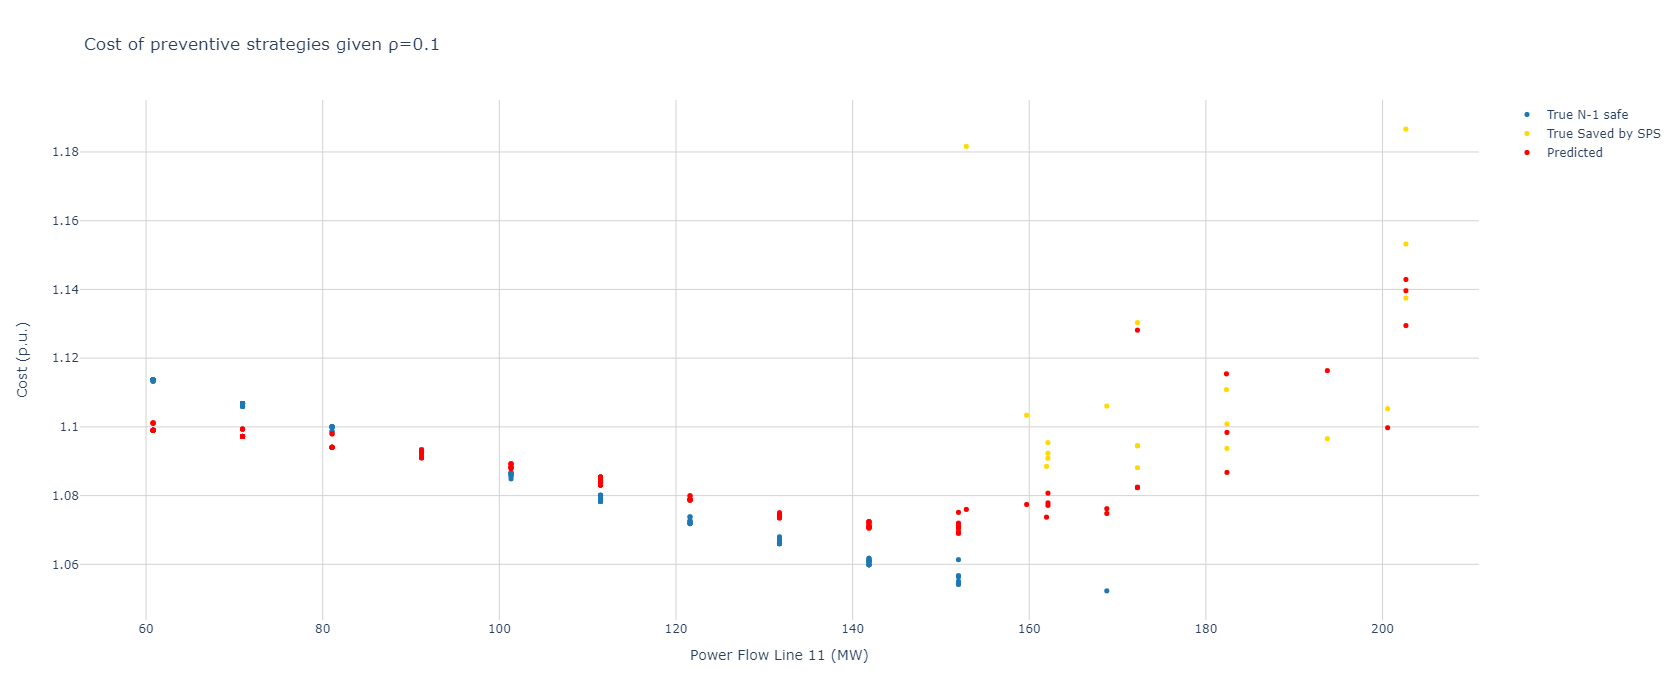

In [145]:
layout = go.Layout(
    title = 'Cost of preventive strategies given ρ={}'.format(failure_rate),
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

groups = ["N-1 safe", "Saved by SPS", "Not N-1 safe"]

colors = ["#1F77B4","#FFDA00", "#FF6600"]

for index, group in enumerate(groups):
    new_df = df_prev[df_prev['corr3'] == group]
    fig.add_trace(go.Scatter(x=new_df["Line11"], y=new_df['total_cost_target'], marker=dict(color=colors[index], size=5), mode='markers', name='True {}'.format(group)))


fig.add_trace(go.Scatter(x=df_prev["Line11"], y=df_prev['total_cost_pred'], mode='markers', marker=dict(color='red', size=5), name="Predicted"))

fig.update_layout(
    xaxis_title='Power Flow Line 11 (MW)',
    yaxis_title='Cost (p.u.)',
    width=1000, height=700
)
fig.show()

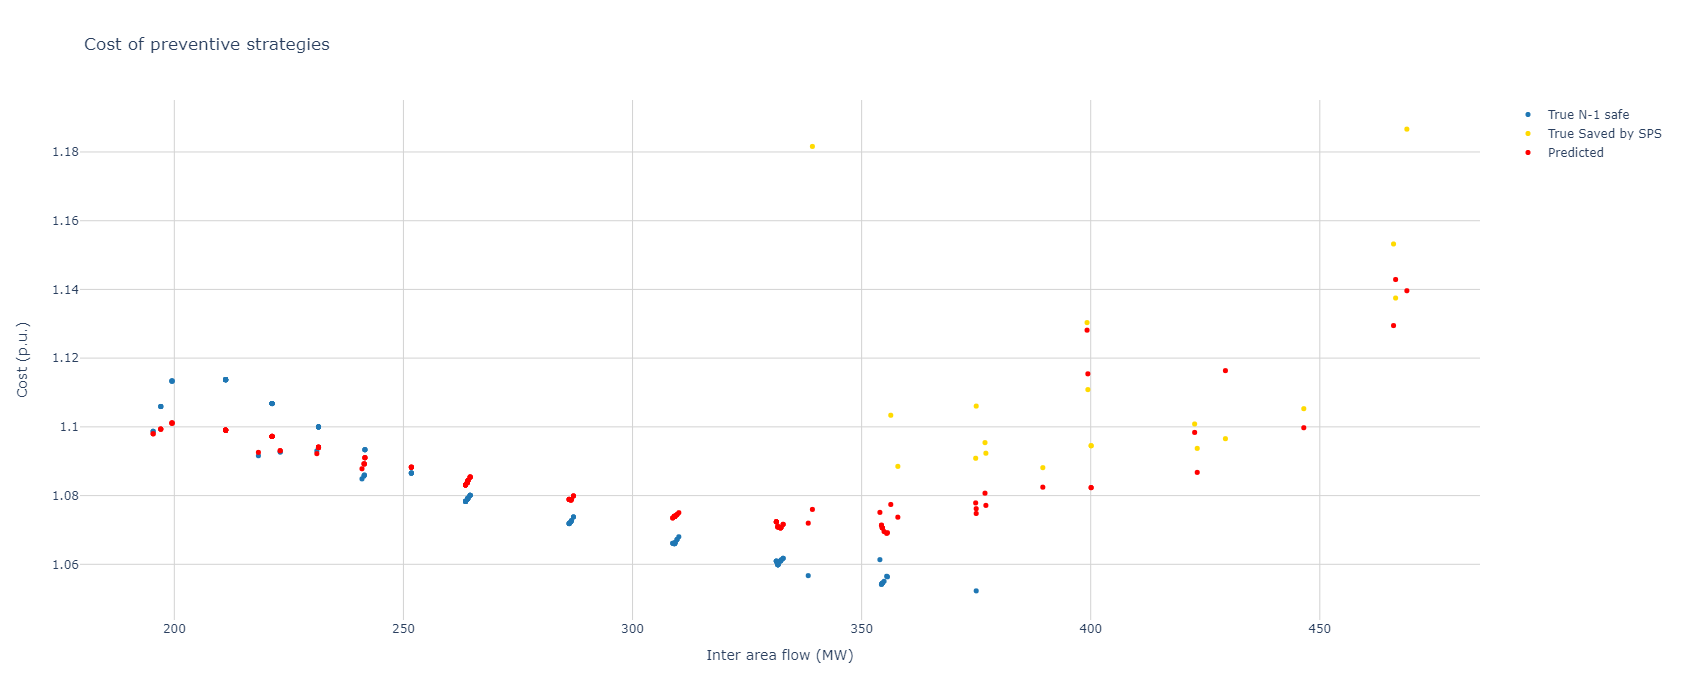

In [143]:
layout = go.Layout(
    title = f'Cost of preventive strategies',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

groups = ["N-1 safe", "Saved by SPS", "Not N-1 safe"]

colors = ["#1F77B4","#FFDA00", "#FF6600"]

for index, group in enumerate(groups):
    new_df = df_prev[df_prev['corr3'] == group]
    fig.add_trace(go.Scatter(x=new_df["inter_area_flow"], y=new_df['total_cost_target'], marker=dict(color=colors[index], size=5), mode='markers', name='True {}'.format(group)))


fig.add_trace(go.Scatter(x=df_prev["inter_area_flow"], y=df_prev['total_cost_pred'], mode='markers', marker=dict(color='red', size=5), name="Predicted"))

fig.update_layout(
    xaxis_title='Inter area flow (MW)',
    yaxis_title='Cost (p.u.)',
    width=1000, height=700
)
fig.show()